# Notebook 01: Exploratory Data Analysis

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scripts.config import DATA_DIR, FIGURE_DIR

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
tr = pd.read_csv(DATA_DIR / 'train.csv')
te = pd.read_csv(DATA_DIR / 'test.csv')
print('train', tr.shape, '| test', te.shape)

train (533465, 17) | test (228629, 16)


1. Datasets

In [3]:
print('Missing Values (train):', int(tr.isna().sum().sum()))
print('Duplicate Rows (building_id):', int(tr.building_id.duplicated().sum()))
display(tr.head())
display(tr[['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']].describe().T)

Missing Values (train): 0
Duplicate Rows (building_id): 0


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


2. Distribusi target
Kelas tidak seimbang → metrik yang dipakai Macro F1, bukan akurasi.

damage_grade
Grade 1    10.3
Grade 2    11.4
Grade 3    17.9
Grade 4    24.1
Grade 5    36.2
Name: proportion, dtype: float64


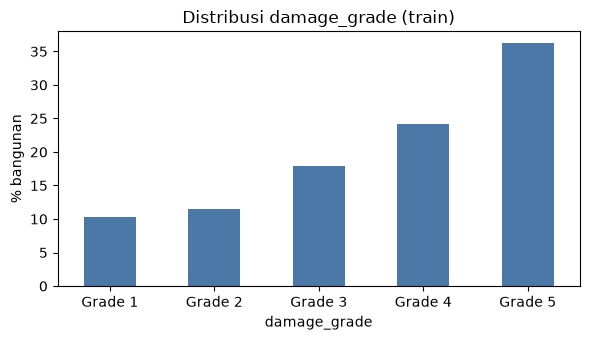

In [4]:
order = [f'Grade {i}' for i in range(1, 6)]
dist = tr.damage_grade.value_counts(normalize=True).reindex(order)
print((dist * 100).round(1))
ax = dist.mul(100).plot.bar(color='#4C78A8', figsize=(6, 3.5), rot=0)
ax.set_ylabel('% bangunan'); ax.set_title('Distribusi damage_grade (train)')
plt.tight_layout(); plt.savefig(FIGURE_DIR / 'target_distribution.png', dpi=130); plt.show()

3. Factor: Jenis bangunan vs tingkat kerusakan

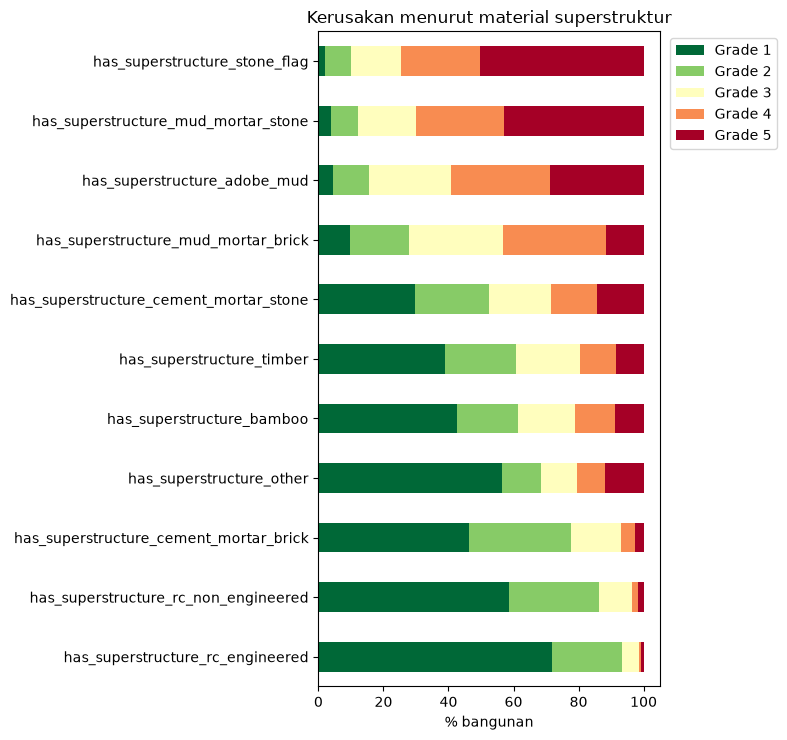

damage_grade,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
superstructure,,,,,
has_superstructure_rc_engineered,71.9,21.4,5.3,0.7,0.7
has_superstructure_rc_non_engineered,58.6,27.6,10.2,1.8,1.8
has_superstructure_cement_mortar_brick,46.4,31.1,15.6,4.3,2.6
has_superstructure_other,56.6,12.0,10.8,8.6,12.0
has_superstructure_bamboo,42.5,18.7,17.5,12.3,8.9
has_superstructure_timber,39.0,21.7,19.8,11.0,8.5
has_superstructure_cement_mortar_stone,29.8,22.6,19.0,14.1,14.4
has_superstructure_mud_mortar_brick,9.8,18.0,29.1,31.4,11.7
has_superstructure_adobe_mud,4.6,11.0,25.1,30.5,28.9


In [5]:
def share_plot(col, fname, title, min_n=500):
    """Gambar proporsi tiap damage_grade untuk setiap nilai ``col`` (urut: rata-rata grade tertinggi di atas)."""
    t = tr.assign(g=tr.damage_grade.str[-1].astype(int))
    keep = t[col].value_counts()[lambda s: s >= min_n].index
    t = t[t[col].isin(keep)]
    ct = pd.crosstab(t[col], t.damage_grade, normalize='index').reindex(columns=order)
    ct = ct.loc[t.groupby(col).g.mean().sort_values().index]
    ax = ct.mul(100).plot.barh(stacked=True, figsize=(8, 0.5 * len(ct) + 2), colormap='RdYlGn_r')
    ax.set_xlabel('% bangunan'); ax.set_ylabel(''); ax.set_title(title)
    ax.legend(title='', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.savefig(FIGURE_DIR / fname, dpi=130); plt.show()
    return ct

ct_sup = share_plot('superstructure', 'damage_by_superstructure.png', 'Kerusakan menurut material superstruktur')
display((ct_sup * 100).round(1))

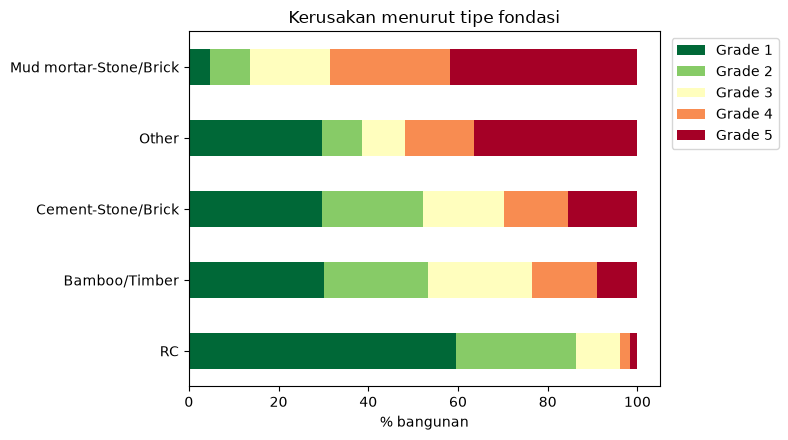

damage_grade,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
foundation_type,,,,,
RC,59.5,26.8,9.8,2.2,1.6
Bamboo/Timber,30.1,23.3,23.2,14.4,9.1
Cement-Stone/Brick,29.6,22.6,18.0,14.3,15.5
Other,29.7,8.9,9.7,15.3,36.5
Mud mortar-Stone/Brick,4.7,8.9,17.9,26.8,41.7


In [6]:
ct_fnd = share_plot('foundation_type', 'damage_by_foundation.png', 'Kerusakan menurut tipe fondasi')
display((ct_fnd * 100).round(1))

4. Factor: Jumlah lantai & umur bangunan

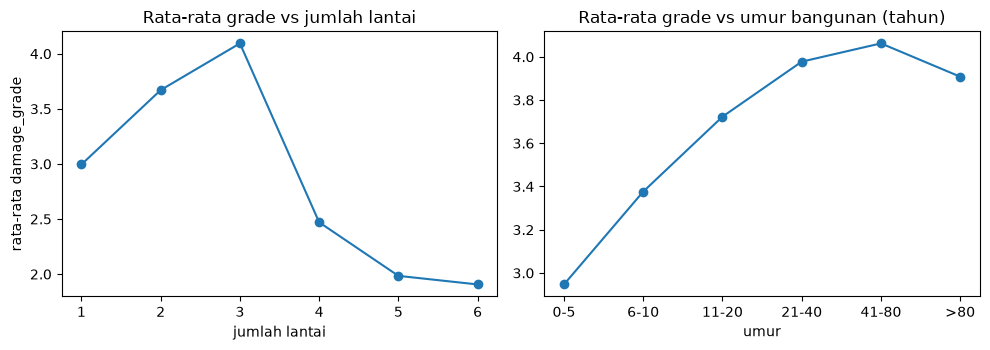

                     mean    size
count_floors_pre_eq              
1                    2.99   83177
2                    3.67  327666
3                    4.09  116918
4                    2.47    4318
5                    1.98    1079
6                    1.91     235
7                    1.94      52
8                    2.56       9
9                    2.82      11
       mean    size
umur               
0-5    2.95   85807
6-10   3.38   84889
11-20  3.72  164574
21-40  3.98  145490
41-80  4.06   44942
>80    3.91    7763


In [7]:
t = tr.assign(g=tr.damage_grade.str[-1].astype(int),
              umur=pd.cut(tr.age_building.clip(upper=200), [-1, 5, 10, 20, 40, 80, 200],
                          labels=['0-5', '6-10', '11-20', '21-40', '41-80', '>80']))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
t.groupby('count_floors_pre_eq').g.agg(['mean', 'size']).query('size >= 200')['mean'].plot(marker='o', ax=ax[0])
ax[0].set_title('Rata-rata grade vs jumlah lantai'); ax[0].set_xlabel('jumlah lantai'); ax[0].set_ylabel('rata-rata damage_grade')
t.groupby('umur', observed=True).g.mean().plot(marker='o', ax=ax[1])
ax[1].set_title('Rata-rata grade vs umur bangunan (tahun)'); ax[1].set_xlabel('umur')
plt.tight_layout(); plt.savefig(FIGURE_DIR / 'damage_by_floors_age.png', dpi=130); plt.show()
print(t.groupby('count_floors_pre_eq').g.agg(['mean', 'size']).round(2))
print(t.groupby('umur', observed=True).g.agg(['mean', 'size']).round(2))

5. Factor: Wilayah


Kerusakan sangat bergantung pada lokasi (jarak ke episentrum), sehingga fitur wilayah/tetangga dipakai di tahap pemodelan.

             mean   size
district_id             
31           2.35  63557
12           2.87  27651
20           2.88  48133
24           3.49  68616
21           3.55  41095
36           3.76  54751
30           3.89  62461
28           4.24  53704
22           4.31  42465
29           4.54   8867
23           4.68  62165


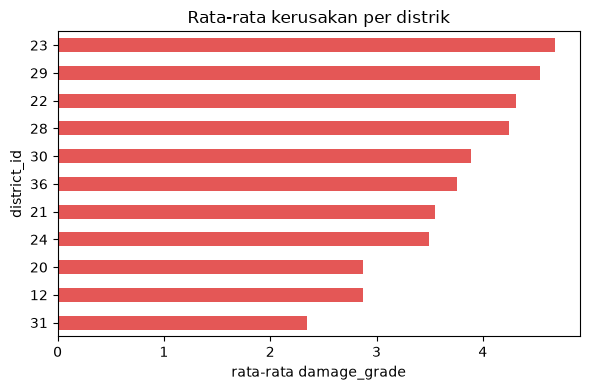

In [8]:
t = tr.assign(g=tr.damage_grade.str[-1].astype(int))
d = t.groupby('district_id').g.agg(['mean', 'size']).sort_values('mean')
print(d.round(2))
ax = d['mean'].plot.barh(figsize=(6, 4), color='#E45756'); ax.set_xlabel('rata-rata damage_grade'); ax.set_title('Rata-rata kerusakan per distrik')
plt.tight_layout(); plt.savefig(FIGURE_DIR / 'damage_by_district.png', dpi=130); plt.show()